**SUMMARY AND STATISTICS**

In [ ]:
import pandas as pd

file_path = r'C:\Users\Lenovo\OneDrive - UPES\Desktop\projects\Long_term_project\Delivery_Logistics\Delivery_Logistics_updated.csv'
try:
    df = pd.read_csv(file_path)
    print(f"Successfully loaded '{file_path}'.")
except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found.")
    exit()


print("\n## 📋 DataFrame Information (df.info())")
df.info()

Successfully loaded 'C:\Users\Lenovo\OneDrive - UPES\Desktop\projects\Long_term_project\Delivery_Logistics\Delivery_Logistics_updated.csv'.

## 📋 DataFrame Information (df.info())
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   delivery_id        25000 non-null  int64  
 1   delivery_partner   25000 non-null  object 
 2   package_type       25000 non-null  object 
 3   vehicle            25000 non-null  object 
 4   vehicle_type       25000 non-null  object 
 5   delivery_mode      25000 non-null  object 
 6   region             25000 non-null  object 
 7   weather_condition  25000 non-null  object 
 8   distance_km        25000 non-null  float64
 9   package_weight_kg  25000 non-null  int64  
 10  Order_Date         25000 non-null  object 
 11  Delivery_Date      25000 non-null  object 
 12  delivery_status    25000 non-null 

In [2]:
print(df.head())

   delivery_id delivery_partner      package_type vehicle        vehicle_type  \
0          251        delhivery  automobile parts    bike      Engine Vehicle   
1          251       xpressbees         cosmetics  ev van  Electronic Vehicle   
2          251        shadowfax         groceries   truck      Engine Vehicle   
3          251              dhl       electronics  ev van  Electronic Vehicle   
4          251              dhl          clothing     van      Engine Vehicle   

  delivery_mode   region weather_condition  distance_km  package_weight_kg  \
0      same day     west             clear        297.0                 47   
1       express  central              cold         89.6                 47   
2       two day     east             rainy        273.5                 27   
3      same day     east              cold        269.7                 13   
4       two day    north             foggy        256.7                 37   

   Order_Date Delivery_Date delivery_status 

In [3]:
print("Missing Values Count ")
print(df.isnull().sum())

Missing Values Count 
delivery_id          0
delivery_partner     0
package_type         0
vehicle              0
vehicle_type         0
delivery_mode        0
region               0
weather_condition    0
distance_km          0
package_weight_kg    0
Order_Date           0
Delivery_Date        0
delivery_status      0
delayed              0
Delievered           0
Failed_Delivery      0
delivery_rating      0
Rating_Review        0
delivery_cost        0
Month Name           0
dtype: int64


In [4]:
print(" Descriptive Statistics")
print(df.describe())

 Descriptive Statistics
        delivery_id   distance_km  package_weight_kg  delivery_rating  \
count  25000.000000  25000.000000       25000.000000     25000.000000   
mean   12500.500000    150.390436          25.150760         3.666000   
std     7212.731974     86.409745          14.371666         1.149964   
min      251.000000      3.600000           1.000000         1.000000   
25%     6250.750000     75.900000          13.000000         3.000000   
50%    12500.500000    151.000000          25.000000         4.000000   
75%    18750.250000    224.900000          38.000000         5.000000   
max    24750.000000    297.100000          50.000000         5.000000   

       delivery_cost  
count   25000.000000  
mean      864.944579  
std       435.712593  
min        95.667400  
25%       490.800000  
50%       867.535000  
75%      1237.910000  
max      1632.720600  


**PLOTS**

In [5]:
pip install altair

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import altair as alt
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:


df_sample = df.sample(n=5000, random_state=42) if len(df) > 5000 else df

chart = (
    alt.Chart(df_sample)
    .mark_circle(opacity=0.7)
    .encode(
        x='distance_km:Q',
        y='delivery_cost:Q',
        color=alt.Color('package_weight_kg:Q', scale=alt.Scale(scheme='viridis')),
        tooltip=['distance_km:Q','package_weight_kg:Q','delivery_cost:Q','delivery_partner:N']
    )
    .properties(width=900, height=480, title="Distance vs Cost (sampled)")
)

chart   # put chart as last line to display in notebook




alt.Chart(...)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16976\2708762564.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rating_delay_counts = df.groupby(['Rating_Review', 'delayed']).size().reset_index(name='Count')


Matplotlib chart saved to rating_vs_delay_bar.png


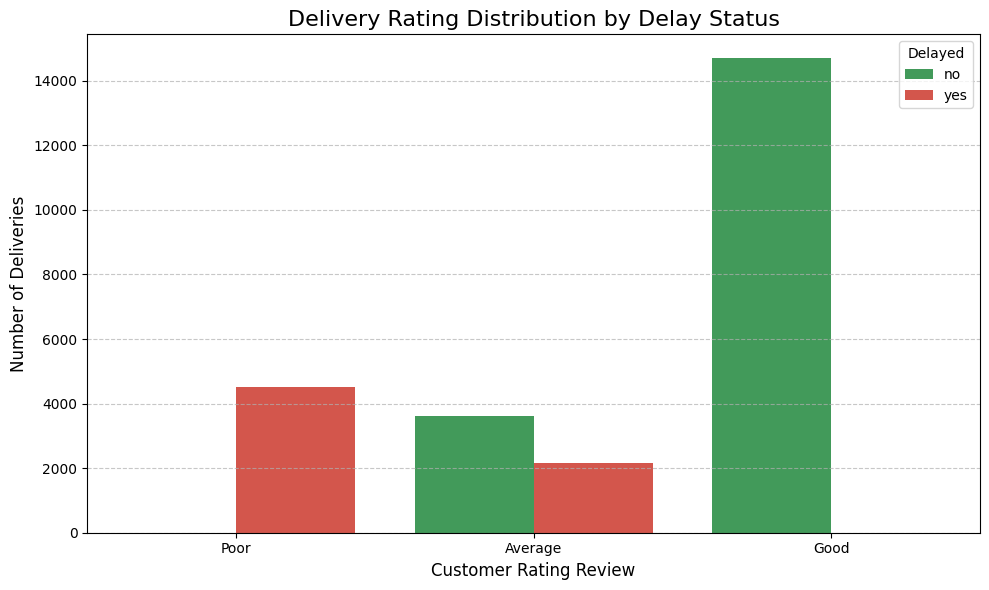

In [8]:
# --- Chart 2: Delivery Rating Distribution vs. Delay Status (Seaborn) ---
# This chart connects operational performance (delay) directly to customer satisfaction (rating).

# Ensure 'Rating_Review' is treated as categorical and ordered for better visualization
rating_order = ['Poor', 'Average', 'Good']
df['Rating_Review'] = pd.Categorical(df['Rating_Review'], categories=rating_order, ordered=True)

# Calculate counts for plotting
rating_delay_counts = df.groupby(['Rating_Review', 'delayed']).size().reset_index(name='Count')

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Rating_Review',
    y='Count',
    hue='delayed',
    data=rating_delay_counts,
    palette=['#34A853', '#EA4335'], # Green for 'no' delay, Red for 'yes' delay
    order=rating_order
)

plt.title('Delivery Rating Distribution by Delay Status', fontsize=16)
plt.xlabel('Customer Rating Review', fontsize=12)
plt.ylabel('Number of Deliveries', fontsize=12)
plt.legend(title='Delayed', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

print("Matplotlib chart saved to rating_vs_delay_bar.png")

Grouped bar plot saved to success_rate_vehicle_weather.png


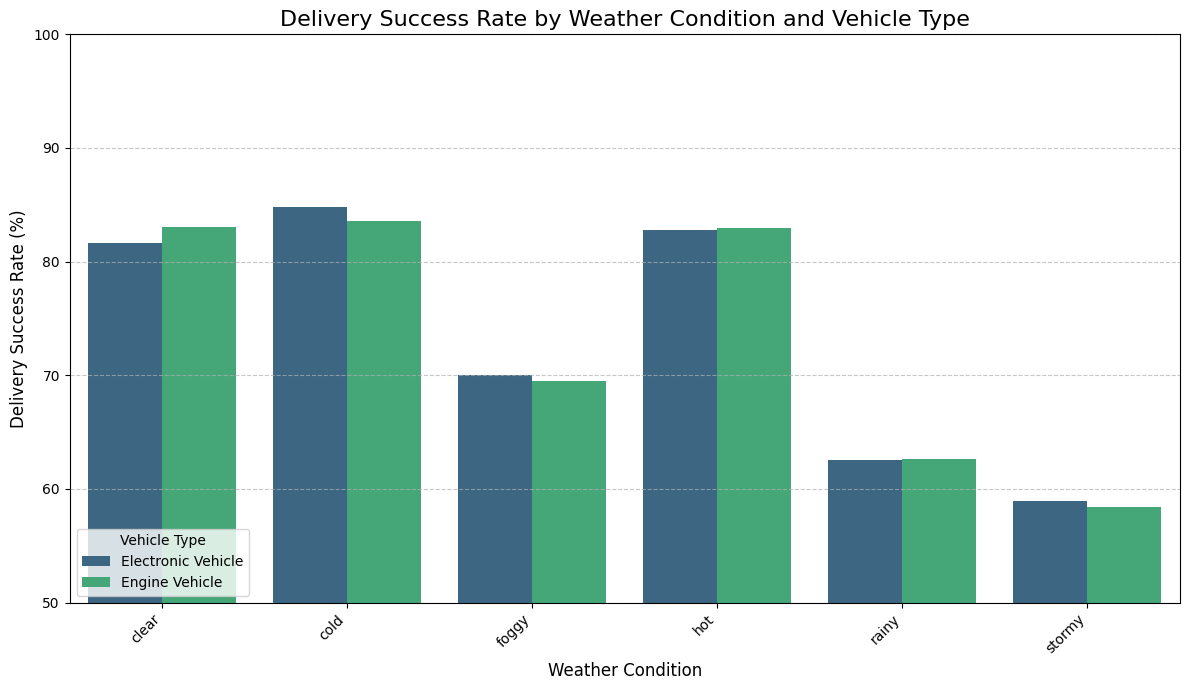

In [9]:
# Success Rate by Vehicle Type and Weather Condition (Grouped Bar Chart) ---
df['is_successful'] = df['delivery_status'].apply(lambda x: 1 if x == 'delivered' else 0)

# Calculate Success Rate (mean of is_successful) grouped by vehicle type and weather
success_rate_grouped = df.groupby(['vehicle_type', 'weather_condition'])['is_successful'].mean().reset_index()
success_rate_grouped['Success_Rate_%'] = (success_rate_grouped['is_successful'] * 100).round(2)

plt.figure(figsize=(12, 7))
sns.barplot(
    x='weather_condition',
    y='Success_Rate_%',
    hue='vehicle_type',
    data=success_rate_grouped,
    palette='viridis'
)

plt.title('Delivery Success Rate by Weather Condition and Vehicle Type', fontsize=16)
plt.xlabel('Weather Condition', fontsize=12)
plt.ylabel('Delivery Success Rate (%)', fontsize=12)
plt.legend(title='Vehicle Type', loc='lower left')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(50, 100) # Zoom in to relevant success rate range
plt.tight_layout()

print("Grouped bar plot saved to success_rate_vehicle_weather.png")




Box plot saved to cost_distribution_failure.png


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16976\1037014681.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


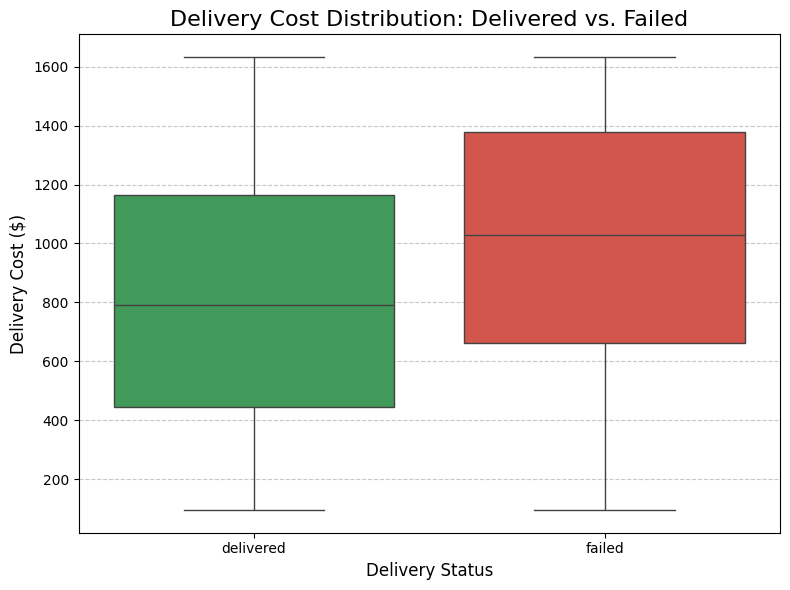

In [10]:
# --- Chart 2: Delivery Cost Distribution for Failed vs. Delivered (Box Plot) ---

# Filter data for only delivered and failed statuses
cost_failure_data = df[df['delivery_status'].isin(['delivered', 'failed'])].copy()

# Ensure delivery_cost is numeric
cost_failure_data['delivery_cost'] = pd.to_numeric(cost_failure_data['delivery_cost'], errors='coerce')
cost_failure_data.dropna(subset=['delivery_cost'], inplace=True)

plt.figure(figsize=(8, 6))
sns.boxplot(
    x='delivery_status',
    y='delivery_cost',
    data=cost_failure_data,
    palette=['#34A853', '#EA4335'] # Green for delivered, Red for failed
)

plt.title('Delivery Cost Distribution: Delivered vs. Failed', fontsize=16)
plt.xlabel('Delivery Status', fontsize=12)
plt.ylabel('Delivery Cost ($)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

print("Box plot saved to cost_distribution_failure.png")

In [11]:

# status_counts already exists, but here’s a safe version:
status_counts = df['delivery_status'].value_counts().reset_index()
status_counts.columns = ['Delivery_Status', 'Count']

# Set correct order: delivered → delayed → failed
status_order = ['delivered', 'delayed', 'failed']
status_counts['Delivery_Status'] = pd.Categorical(
    status_counts['Delivery_Status'], 
    categories=status_order, 
    ordered=True
)
status_counts = status_counts.sort_values("Delivery_Status")

# ---------- DISPLAY FUNNEL CHART ----------
funnel_chart = (
    alt.Chart(status_counts)
    .mark_bar(size=45)
    .encode(
        x=alt.X('Count', title='Number of Deliveries'),
        y=alt.Y('Delivery_Status', sort=status_order, title='Delivery Stage'),
        color=alt.Color('Delivery_Status',
                       scale=alt.Scale(domain=status_order)),
        tooltip=['Delivery_Status', 'Count']
    )
    .properties(
        title='Delivery Final Status Flow (Funnel View)',
        width=1000,   # better width
        height=380    # better height
    )
    .configure_axis(
        labelFontSize=14,
        titleFontSize=16
    )
    .configure_title(
        fontSize=20,
        anchor='start'
    )
    
)

# 👉 Display inside VS Code Jupyter
funnel_chart


alt.Chart(...)

Matplotlib Line plot saved to monthly_failure_rate_line.png


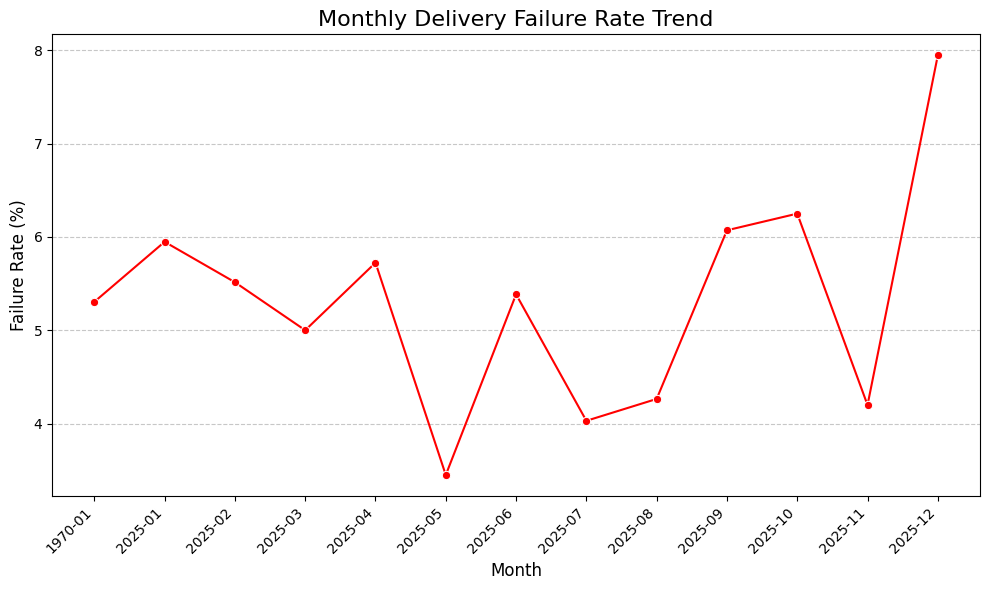

In [12]:
# --- Plot 3: Line Plot: Monthly Failure Rate Trend (Matplotlib) ---

# Prepare data for time series analysis
date_cols = ['Order_Date', 'Delivery_Date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce', dayfirst=True)

# Filter out bad dates and create month/year for grouping
df_ts = df[df['Order_Date'].notna()].copy()
df_ts['YearMonth'] = df_ts['Order_Date'].dt.to_period('M')

# Define failure (1 if failed, 0 otherwise)
df_ts['is_failed'] = df_ts['delivery_status'].apply(lambda x: 1 if x == 'failed' else 0)

# Calculate monthly failure rate
monthly_failure_rate = df_ts.groupby('YearMonth').agg(
    Total_Deliveries=('delivery_id', 'count'),
    Failure_Rate=('is_failed', 'mean')
).reset_index()

monthly_failure_rate['Failure_Rate_%'] = monthly_failure_rate['Failure_Rate'] * 100
monthly_failure_rate['YearMonth_Str'] = monthly_failure_rate['YearMonth'].astype(str)

plt.figure(figsize=(10, 6))
sns.lineplot(
    x='YearMonth_Str',
    y='Failure_Rate_%',
    data=monthly_failure_rate,
    marker='o',
    color='red'
)

plt.title('Monthly Delivery Failure Rate Trend', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Failure Rate (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

print("Matplotlib Line plot saved to monthly_failure_rate_line.png")




    region  Total_Deliveries  Failure_Rate  Failure_Rate_%
0  central              5060      0.056522            5.65
4     west              5095      0.056330            5.63
3    south              4977      0.055053            5.51
1     east              4919      0.049807            4.98
2    north              4949      0.047686            4.77


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16976\2652379339.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


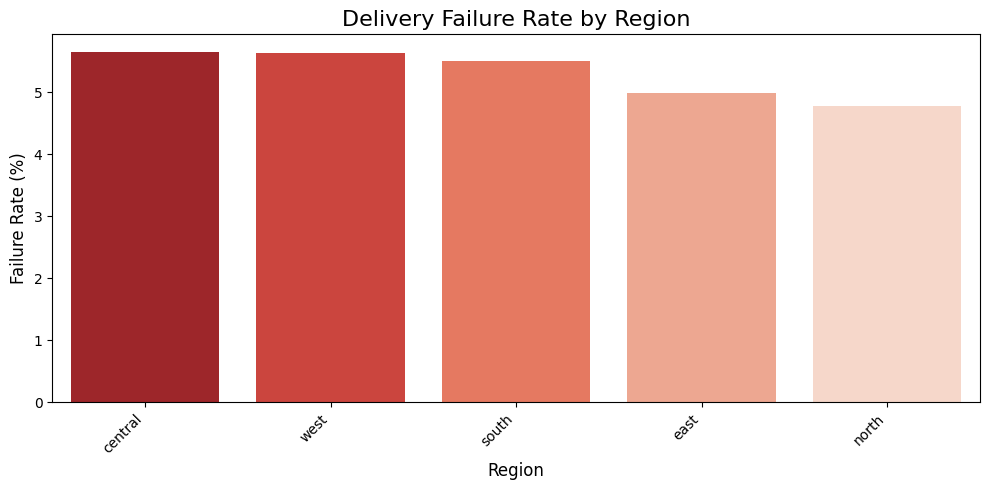

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -------- 1. Load & Clean Data --------
df = pd.read_csv("Delivery_Logistics_updated.csv")

# Normalize columns
df.columns = df.columns.str.strip()

# If "is_failed" column does NOT exist, create it from delivery_status
if "is_failed" not in df.columns:
    df["is_failed"] = df["delivery_status"].str.lower().eq("failed")

# Convert boolean → numeric (True=1, False=0)
df["is_failed_numeric"] = df["is_failed"].astype(int)

# Keep required columns only
df = df[["region", "delivery_id", "is_failed_numeric"]].dropna()

# -------- 2. Calculate Failure Rate by Region --------
regional_failure_rate = (
    df.groupby("region")
      .agg(
          Total_Deliveries=("delivery_id", "count"),
          Failure_Rate=("is_failed_numeric", "mean")
      )
      .reset_index()
)

# Convert to percentage
regional_failure_rate["Failure_Rate_%"] = (regional_failure_rate["Failure_Rate"] * 100).round(2)

# Sort descending by failure rate
regional_failure_rate = regional_failure_rate.sort_values("Failure_Rate_%", ascending=False)

print(regional_failure_rate.head())

# -------- 3. Plot Failure Rates --------
plt.figure(figsize=(10, 5))
sns.barplot(
    data=regional_failure_rate,
    x="region",
    y="Failure_Rate_%",
    palette="Reds_r"   # simple clean palette
)

plt.title("Delivery Failure Rate by Region", fontsize=16)
plt.xlabel("Region", fontsize=12)
plt.ylabel("Failure Rate (%)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


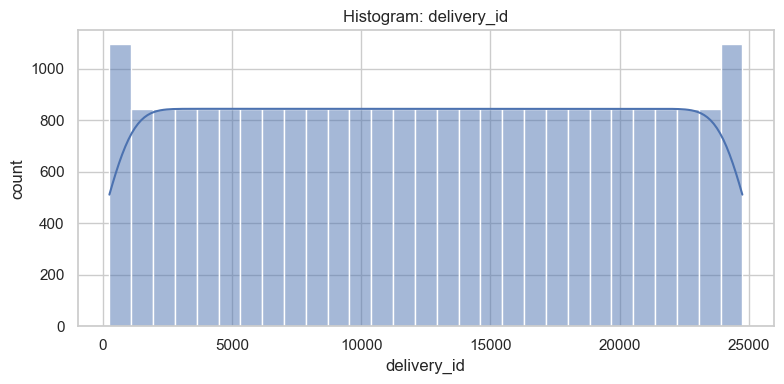

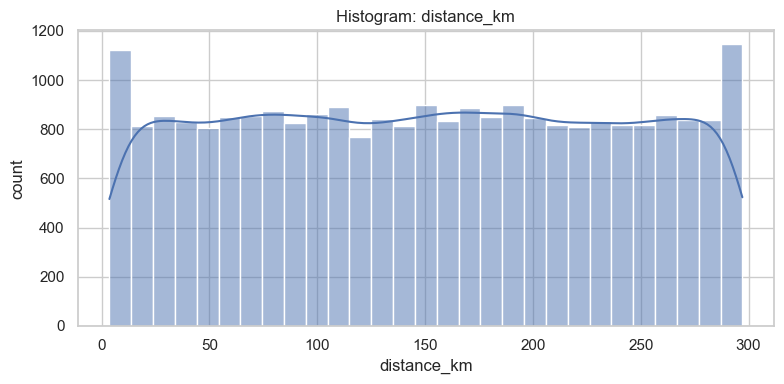

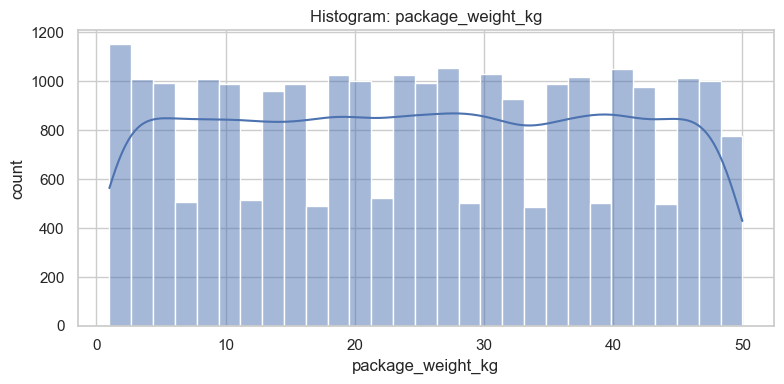

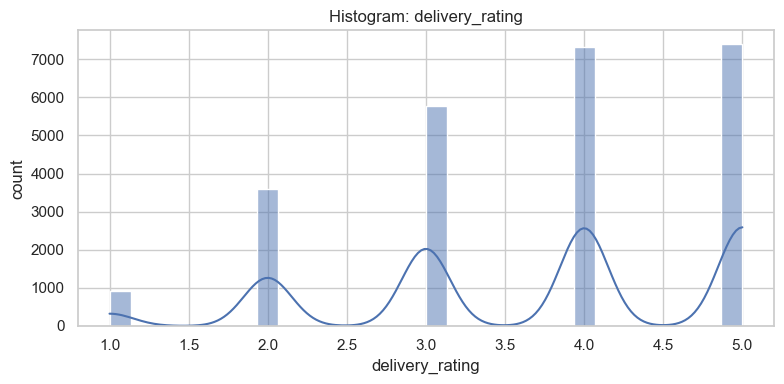

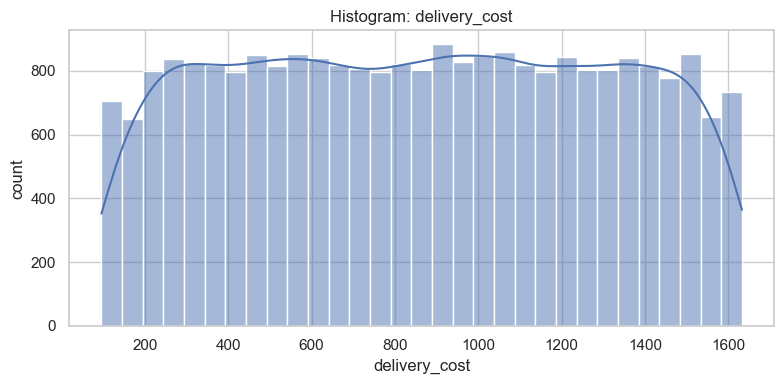

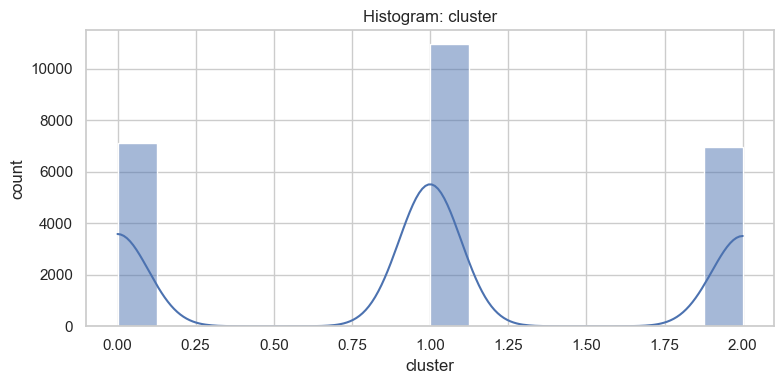

In [21]:

df.columns = df.columns.str.strip().str.replace(" ", "_", regex=False).str.replace("-", "_", regex=False).str.lower()

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
sns.set(style="whitegrid")

for col in numeric_cols:
    plt.figure(figsize=(8,4))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Histogram: {col}")
    plt.xlabel(col)
    plt.ylabel("count")
    plt.tight_layout()
    plt.show()


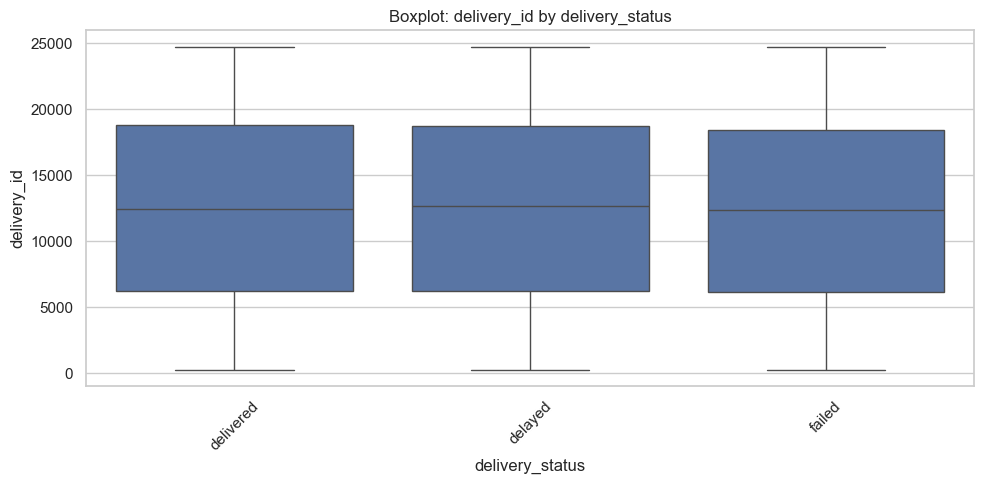

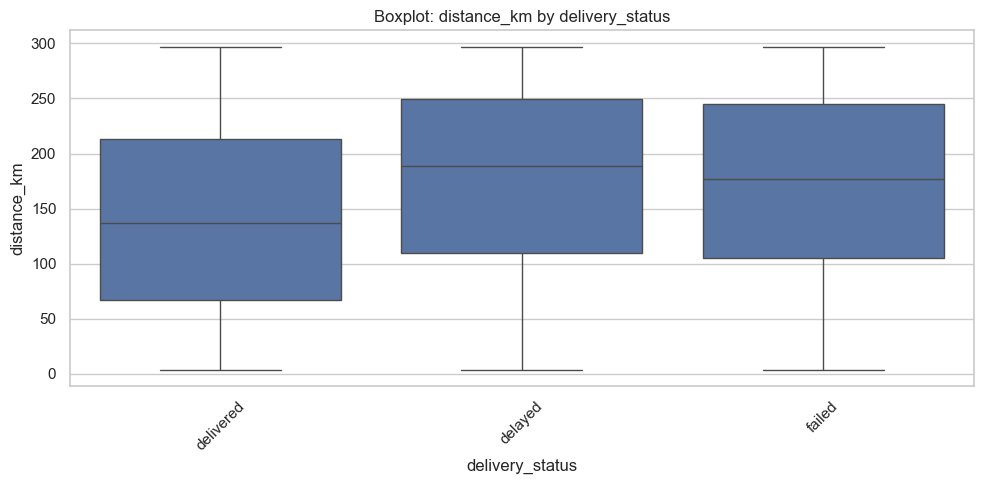

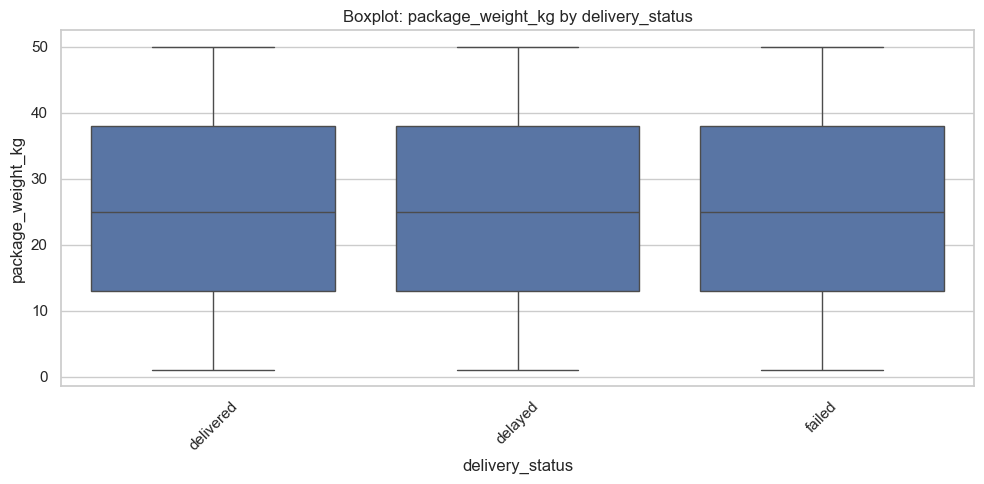

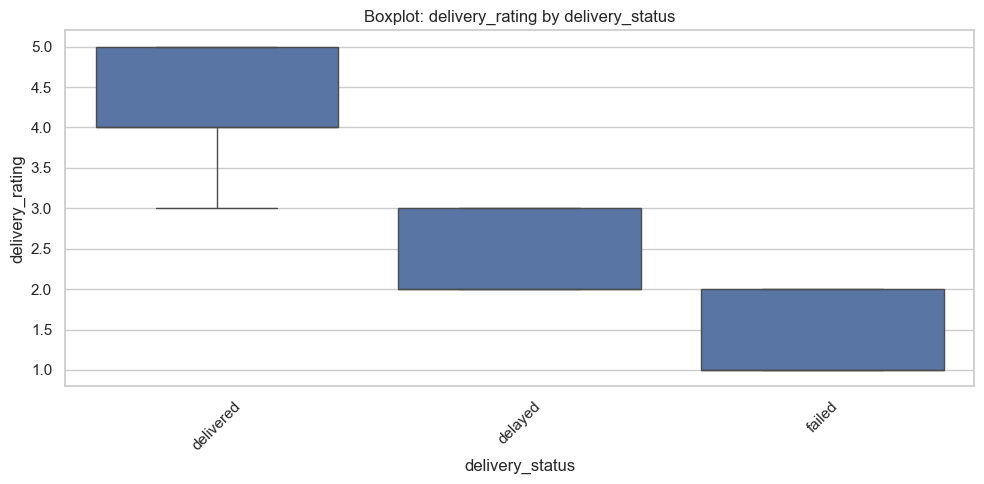

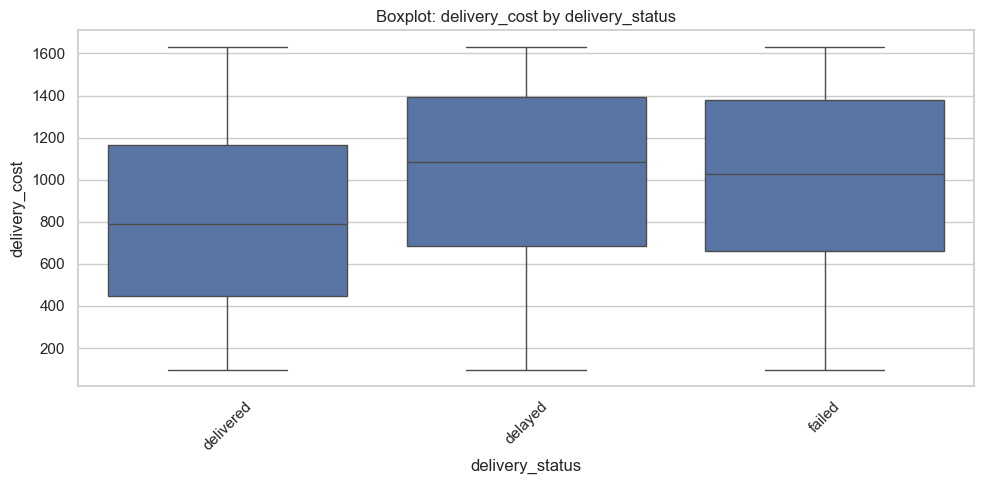

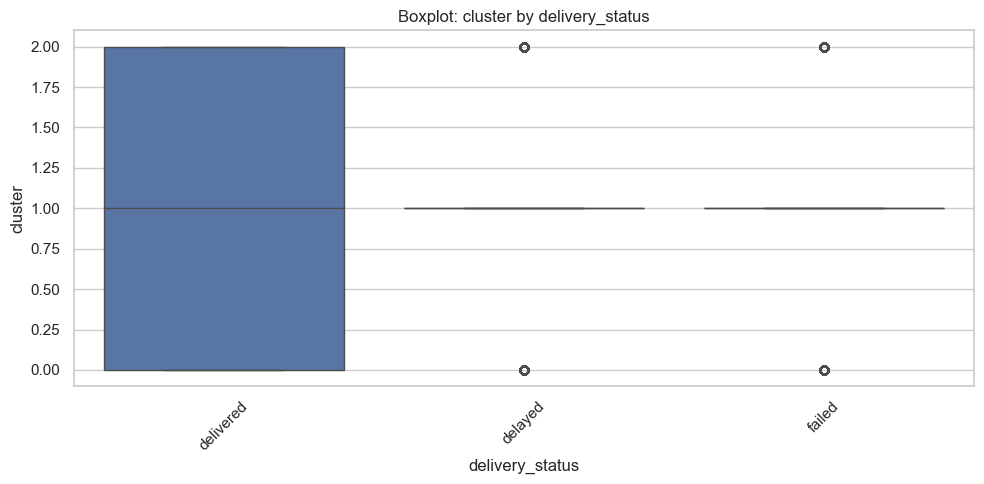

In [22]:

df.columns = df.columns.str.strip().str.replace(" ", "_", regex=False).str.replace("-", "_", regex=False).str.lower()

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_priority = ["delivery_status","region","vehicle_type","weather_condition","delivery_partner","package_type","month_name","cluster"]
cat_cols = [c for c in cat_priority if c in df.columns]
if not cat_cols:
    cat_cols = df.select_dtypes(include=["object","category"]).columns.tolist()

sns.set(style="whitegrid")
if cat_cols and numeric_cols:
    cat = cat_cols[0]
    for num in numeric_cols:
        plt.figure(figsize=(10,5))
        sns.boxplot(x=df[cat].astype(str), y=df[num])
        plt.title(f"Boxplot: {num} by {cat}")
        plt.xlabel(cat)
        plt.ylabel(num)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
else:
    print("Need at least one categorical and one numeric column.")


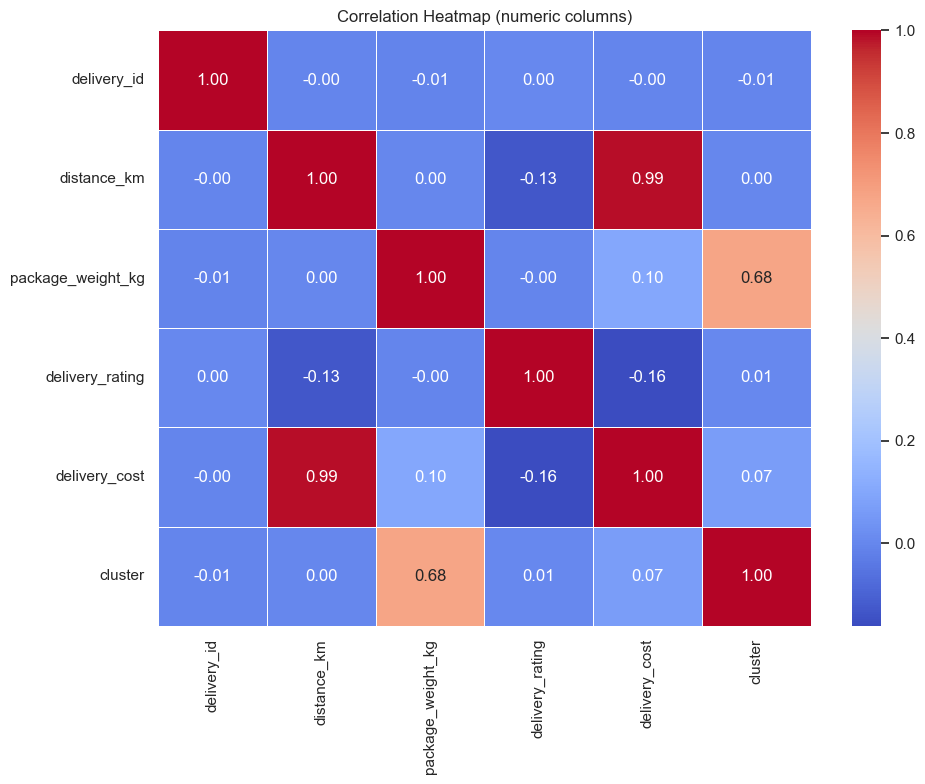

In [24]:

df.columns = df.columns.str.strip().str.replace(" ", "_", regex=False).str.replace("-", "_", regex=False).str.lower()

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if numeric_cols:
    corr = df[numeric_cols].corr()
    plt.figure(figsize=(10,8))
    sns.heatmap(corr, annot=True, fmt=".2f", linewidths=.5, cmap="coolwarm")
    plt.title("Correlation Heatmap (numeric columns)")
    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns found for correlation heatmap.")


**MODELING**

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# -----------------------------------------
# LOAD DATA
# -----------------------------------------
df = pd.read_csv("Delivery_Logistics_updated.csv")

# Clean needed columns
df['delivery_cost'] = pd.to_numeric(df['delivery_cost'], errors='coerce')
df['distance_km'] = pd.to_numeric(df['distance_km'], errors='coerce')
df['package_weight_kg'] = pd.to_numeric(df['package_weight_kg'], errors='coerce')

df['delivery_status'] = df['delivery_status'].astype(str).str.lower().str.strip()

# -----------------------------------------
# 1) BASIC STATISTICAL TESTS
# -----------------------------------------

print("\n=== 1. STATISTICAL TESTS ===")

# --- T-TEST (delivery cost express vs standard) --- (significant difference between mean of 2 groups)
group1 = df[df['delivery_mode'] == 'express']['delivery_cost'].dropna()
group2 = df[df['delivery_mode'] == 'standard']['delivery_cost'].dropna()

if len(group1) > 2 and len(group2) > 2:
    t, p = stats.ttest_ind(group1, group2, equal_var=False)
    print("T-test: Express vs Standard delivery cost")
    print("t =", round(t, 3), "  p =", round(p, 4))
else:
    print("T-test skipped: not enough data.")


# -----------------------------------------
# 2) SIMPLE PREDICTIVE MODEL (Classification)
# -----------------------------------------

print("\n=== 2. PREDICTIVE MODEL (Logistic Regression) ===")

# Keep only delivered vs failed for simplicity
df2 = df[df['delivery_status'].isin(['delivered', 'failed'])].copy()

# Encode target: delivered=1, failed=0
df2['target'] = df2['delivery_status'].map({'delivered': 1, 'failed': 0})

# Features (simple numeric)
X = df2[['distance_km', 'package_weight_kg', 'delivery_cost']].fillna(0)
y = df2['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy =", round(acc, 3))


# -----------------------------------------
# 3) BASIC CLUSTERING MODEL (K-Means)
# -----------------------------------------

print("\n=== 3. CLUSTERING (K-Means) ===")

cluster_data = df[['distance_km', 'package_weight_kg', 'delivery_cost']].dropna()

# Scale features (basic)
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_data)

kmeans = KMeans(n_clusters=3)
labels = kmeans.fit_predict(cluster_scaled)

print("K-Means cluster labels assigned:", np.unique(labels))

# Add cluster column if needed
df['cluster'] = np.nan
df.loc[cluster_data.index, 'cluster'] = labels




=== 1. STATISTICAL TESTS ===
T-test: Express vs Standard delivery cost
t = 7.878   p = 0.0

Chi-square Test: Weather vs Delivery Status
chi2 = 1359.968   p = 0.0

=== 2. PREDICTIVE MODEL (Logistic Regression) ===
Logistic Regression Accuracy = 0.937

=== 3. CLUSTERING (K-Means) ===
K-Means cluster labels assigned: [0 1 2]
